# IFCNN (general image fusion network)

Fusion method for the `fusion/` pipeline. Save this notebook as `fusion/methods/ifcnn.ipynb`.

- **Input:** `fusion/data/<SOURCE>/` with `rgb/` + `ir/` image sequences (same filenames, frame-aligned), or `visible.mp4` + `thermal.mp4`.
- **Output:** `fusion/out/ifcnn_<SOURCE>.mp4` (grayscale fused video, same resolution as the input).
- **Method:** IFCNN from [uzeful/IFCNN](https://github.com/uzeful/IFCNN). Code and the released snapshots are cloned on first run into `fusion/methods/_vendor/IFCNN/`. Uses the repo's infrared-visible recipe (`MAX` fusion scheme). If you compare several schemes, change `METHOD` (e.g. `ifcnn_sum`) so the outputs don't overwrite each other.

Set `SOURCE`, select the `.venv` kernel, run all cells, then score the result with `fusion/FUSION_EVALUATION.ipynb`.

In [1]:
SOURCE = 'car_008_haze_50'            # folder name inside fusion/data/
METHOD = 'ifcnn'                     # output file: fusion/out/<METHOD>_<SOURCE>.mp4

SCALE = 0.5                   # fuse at this fraction of the input size (output is resized back to full size)
MAX_FRAMES = None             # None = all frames, or an int to fuse only the first N
FPS = 30.0                    # frame rate for image-sequence inputs (videos keep their own)
OVERWRITE = True              # False = skip if the output already exists
PREVIEW_FRAME = 10            # frame index shown in the preview at the end

IFCNN_SCHEME = 'MAX'          # 'MAX' (repo's choice for infrared-visible), 'SUM' or 'MEAN'
IFCNN_CKPT = None             # None -> IFCNN/Code/snapshots/IFCNN-<scheme>.pth

In [2]:
import os, sys, subprocess, time, importlib
from itertools import islice
from pathlib import Path

def _need(mod, pip_name=None):                       # fallback if requirements.txt was not installed
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_name or mod], check=True)

for _m, _p in [('numpy', None), ('cv2', 'opencv-python'), ('torch', None), ('torchvision', None), ('tqdm', None), ('matplotlib', None)]:
    _need(_m, _p)

import numpy as np, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

def find_fusion_dir():
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if d.name == 'fusion' and (d / 'data').is_dir():
            return d
        if (d / 'fusion' / 'data').is_dir():
            return d / 'fusion'
    raise FileNotFoundError('Could not find fusion/data from %s. Start Jupyter inside the repo.' % here)

FUSION_DIR = find_fusion_dir()
DATA_DIR, OUT_DIR = FUSION_DIR / 'data', FUSION_DIR / 'out'
VENDOR = FUSION_DIR / 'methods' / '_vendor'          # third-party code is cloned here (add to .gitignore)

def fetch_repo(name, url):
    d = VENDOR / name
    if not d.is_dir():
        VENDOR.mkdir(parents=True, exist_ok=True)
        subprocess.run(['git', 'clone', '--depth', '1', url, str(d)], check=True)
    return d

def pick_ckpt(user_value, default):
    p = Path(user_value) if user_value else Path(default)
    if not p.exists():
        raise FileNotFoundError('Checkpoint not found: %s (set the *_CKPT option in the config cell)' % p)
    return p

print('fusion dir:', FUSION_DIR)
print('sources   :', sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

fusion dir: /home/marco/Code/Uppsala/VidHance/vidhance-extendview/fusion
sources   : ['car_008', 'car_008_haze_50']


In [3]:
REPO_DIR = fetch_repo('IFCNN', 'https://github.com/uzeful/IFCNN.git')
CODE_DIR = REPO_DIR / 'Code'                         # model.py, utils/ and snapshots/ live here
sys.path.insert(0, str(CODE_DIR))
print(sorted(p.name for p in CODE_DIR.iterdir()))

Cloning into '/home/marco/Code/Uppsala/VidHance/vidhance-extendview/fusion/methods/_vendor/IFCNN'...


['IFCNN_Main.py', 'IFCNN_Notebook.ipynb', 'datasets', 'model.py', 'results', 'snapshots', 'utils']


In [4]:
import torchvision.models as tvm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

from model import IFCNN          # IFCNN/Code/model.py

SCHEMES = {'MAX': 0, 'SUM': 1, 'MEAN': 2}
ifcnn_ckpt = pick_ckpt(IFCNN_CKPT, CODE_DIR / 'snapshots' / ('IFCNN-%s.pth' % IFCNN_SCHEME))
print(ifcnn_ckpt)

# The repo's myIFCNN() downloads ImageNet ResNet-101 only to get conv1, but the released
# snapshots already contain conv1.weight, so build the backbone without pretrained weights
# and load everything strictly from the snapshot.
ifcnn_model = IFCNN(tvm.resnet101(weights=None), fuse_scheme=SCHEMES[IFCNN_SCHEME])
ifcnn_model.load_state_dict(torch.load(ifcnn_ckpt, map_location='cpu'), strict=True)
ifcnn_model.eval().to(DEVICE)

device: cpu
/home/marco/Code/Uppsala/VidHance/vidhance-extendview/fusion/methods/_vendor/IFCNN/Code/snapshots/IFCNN-MAX.pth


/home/marco/Code/Uppsala/VidHance/vidhance-extendview/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


IFCNN(
  (conv2): ConvBlock(
    (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
  )
  (conv3): ConvBlock(
    (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
  )
  (conv4): Conv2d(64, 3, kernel_size=(1, 1), stride=(1, 1))
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=1, bias=False)
)

In [5]:
@torch.no_grad()
def fuse_pair(vis_gray, ir_gray):
    # Same recipe as the repo's infrared-visual demo (IFCNN_Main.py): grayscale images are
    # replicated to 3 channels, mean=0 / std=1 (i.e. plain [0, 1] input), and the 3-channel
    # output is converted back to gray. IFCNN is fully convolutional, so any frame size works.
    def to_t(g):
        t = torch.from_numpy(g.astype(np.float32) / 255.0)[None, None]
        return t.repeat(1, 3, 1, 1).to(DEVICE)
    out = ifcnn_model(to_t(vis_gray), to_t(ir_gray))[0].clamp(0, 1).cpu().numpy() * 255.0   # 3 x H x W (RGB)
    gray = cv2.cvtColor(out.transpose(1, 2, 0).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    return gray

In [6]:
# Reading a scene from fusion/data/<SOURCE>/
import re
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')
RGB_DIRS = ('rgb', 'visible', 'vis', 'vi', 'color')
IR_DIRS = ('ir', 'thermal', 'infrared', 't')
RGB_VIDEOS = ('visible.mp4', 'rgb.mp4')
IR_VIDEOS = ('thermal.mp4', 'ir.mp4')

def rescale(img):
    return img if SCALE == 1 else cv2.resize(img, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA)

def _natural(p):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', p.name)]

def _find(d, names, want_dir):
    for p in sorted(d.iterdir()):
        if p.name.lower() in names and (p.is_dir() if want_dir else p.is_file()):
            return p

def image_pairs(rgb_dir, ir_dir):
    rgb = {p.name: p for p in sorted(rgb_dir.iterdir(), key=_natural) if p.suffix.lower() in IMG_EXT}
    ir = {p.name: p for p in sorted(ir_dir.iterdir(), key=_natural) if p.suffix.lower() in IMG_EXT}
    names = sorted(set(rgb) & set(ir), key=lambda n: _natural(Path(n)))
    if names:
        pairs = [(rgb[n], ir[n]) for n in names]
    else:
        print('WARNING: rgb/ and ir/ share no filenames, pairing by sorted position')
        a, b = sorted(rgb.values(), key=_natural), sorted(ir.values(), key=_natural)
        pairs = list(zip(a, b))
    def gen():
        for a, b in pairs:
            v, t = cv2.imread(str(a), cv2.IMREAD_COLOR), cv2.imread(str(b), cv2.IMREAD_GRAYSCALE)
            if v is None or t is None:
                raise IOError('Could not read %s / %s' % (a, b))
            yield v, t
    return len(pairs), FPS, gen()

def video_pairs(rgb_path, ir_path):
    a, b = cv2.VideoCapture(str(rgb_path)), cv2.VideoCapture(str(ir_path))
    if not (a.isOpened() and b.isOpened()):
        raise IOError('Could not open %s / %s' % (rgb_path, ir_path))
    n = min(int(a.get(cv2.CAP_PROP_FRAME_COUNT)), int(b.get(cv2.CAP_PROP_FRAME_COUNT)))
    fps = a.get(cv2.CAP_PROP_FPS) or FPS
    def gen():
        try:
            while True:
                ok1, v = a.read(); ok2, t = b.read()
                if not (ok1 and ok2):
                    break
                yield v, cv2.cvtColor(t, cv2.COLOR_BGR2GRAY)
        finally:
            a.release(); b.release()
    return n, fps, gen()

def open_pairs(src_dir):
    rgb_dir, ir_dir = _find(src_dir, RGB_DIRS, True), _find(src_dir, IR_DIRS, True)
    if rgb_dir and ir_dir:
        return image_pairs(rgb_dir, ir_dir)
    rgb_v, ir_v = _find(src_dir, RGB_VIDEOS, False), _find(src_dir, IR_VIDEOS, False)
    if rgb_v and ir_v:
        return video_pairs(rgb_v, ir_v)
    raise FileNotFoundError('%s needs rgb/ + ir/ folders or visible.mp4 + thermal.mp4, found: %s'
                            % (src_dir, sorted(p.name for p in src_dir.iterdir())))

def make_writer(path, fps, size):
    for code in ('avc1', 'mp4v'):                   # H.264 if this OpenCV build has it, else MPEG-4 (an 'avc1 / Failed to initialize VideoWriter' log line is harmless)
        w = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*code), fps, size)
        if w.isOpened():
            return w
    raise RuntimeError('OpenCV could not open a video writer for %s' % path)

In [7]:
src_dir = DATA_DIR / SOURCE
if not src_dir.is_dir():
    raise FileNotFoundError('fusion/data/%s not found. Available: %s'
                            % (SOURCE, sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())))
out_path = OUT_DIR / ('%s_%s.mp4' % (METHOD, SOURCE))
OUT_DIR.mkdir(parents=True, exist_ok=True)

if out_path.exists() and not OVERWRITE:
    print('exists, skipping:', out_path)
else:
    n_total, fps, frames = open_pairs(src_dir)
    if MAX_FRAMES:
        n_total = min(n_total, MAX_FRAMES) if n_total else MAX_FRAMES
    tmp_path = OUT_DIR / ('.%s_%s.partial.mp4' % (METHOD, SOURCE))   # renamed only when finished
    writer, done, preview, t0 = None, 0, None, time.time()
    try:
        for i, (rgb, ir) in enumerate(tqdm(islice(frames, MAX_FRAMES), total=n_total or None)):
            H, W = rgb.shape[:2]
            if ir.shape[:2] != (H, W):
                ir = cv2.resize(ir, (W, H))
            g = fuse_pair(rescale(cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY)), rescale(ir))
            if DEVICE == 'cuda':
                torch.cuda.synchronize()
            if g.shape[:2] != (H, W):
                g = cv2.resize(g, (W, H), interpolation=cv2.INTER_LINEAR)
            if writer is None:
                writer = make_writer(tmp_path, fps, (W, H))
            writer.write(cv2.cvtColor(g, cv2.COLOR_GRAY2BGR))
            if i == PREVIEW_FRAME or (preview is None and i == (n_total or 1) - 1):
                preview = (rgb, ir, g, i)
            done += 1
    finally:
        if writer is not None:
            writer.release()
        frames.close()
    if done == 0:
        raise RuntimeError('No frames were read from %s' % src_dir)
    os.replace(tmp_path, out_path)
    sec = time.time() - t0
    print('%d frames in %.1fs (%.2f fps on %s) -> %s' % (done, sec, done / sec, DEVICE, out_path))

  0%|          | 0/150 [00:00<?, ?it/s]

[h264_v4l2m2m @ 0x1831f300] Could not find a valid device
[h264_v4l2m2m @ 0x1831f300] can't configure encoder
[ERROR:0@11.288] global cap_ffmpeg_impl.hpp:3568 open Could not open codec h264_v4l2m2m, error: Unspecified error (-22)
[ERROR:0@11.288] global cap_ffmpeg_impl.hpp:3585 open VIDEOIO/FFMPEG: Failed to initialize VideoWriter


150 frames in 154.8s (0.97 fps on cpu) -> /home/marco/Code/Uppsala/VidHance/vidhance-extendview/fusion/out/ifcnn_car_008_haze_50.mp4


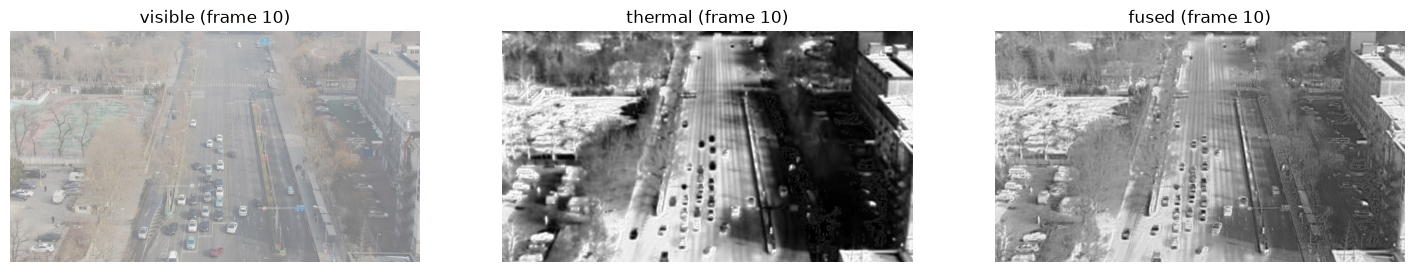

Next: run fusion/FUSION_EVALUATION.ipynb to score ifcnn_car_008_haze_50.mp4


In [8]:
if 'preview' in globals() and preview is not None:
    rgb, ir, g, i = preview
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, img, title in zip(axes, [cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB), ir, g], ['visible', 'thermal', 'fused']):
        ax.imshow(img, cmap=None if img.ndim == 3 else 'gray'); ax.set_title('%s (frame %d)' % (title, i)); ax.axis('off')
    plt.show()
print('Next: run fusion/FUSION_EVALUATION.ipynb to score', out_path.name)